--- Starting Optimized Data Collection ---
Fetching 9 EIA Variables...
Fetching 7 FRED Variables...

Merging and Cleaning...
SUCCESS. Final Dataset Shape: (407, 17)
Date Range: 1990-01-31 to 2023-11-30

Saved to 'oil_market_data_complete.csv'


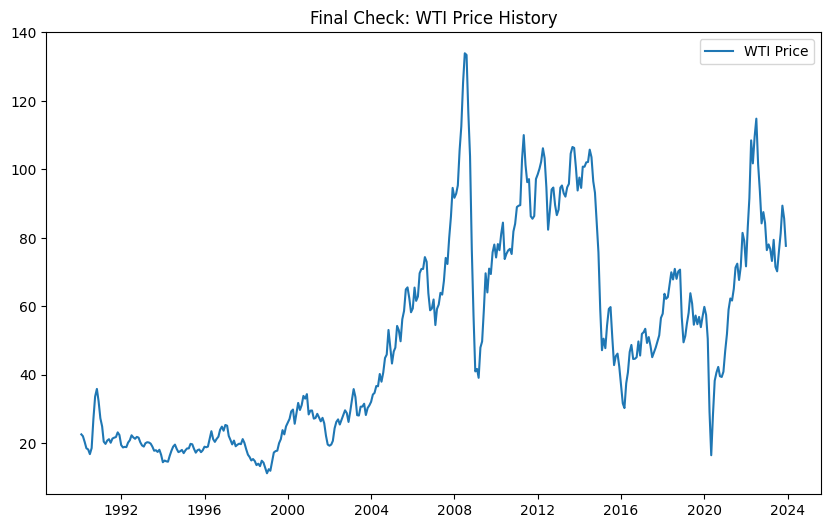

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import datetime
import requests
!pip install fredapi
from fredapi import Fred

# API Keys
import os
EIA_API_KEY = os.getenv("EIA_API_KEY", "YOUR_EIA_KEY_HERE")
FRED_API_KEY = os.getenv("FRED_API_KEY", "YOUR_FRED_KEY_HERE")

# Initialize FRED API
fred = Fred(api_key=FRED_API_KEY)

def fetch_eia_v2_steo(series_id, api_key):
    """
    Fetches data from the new EIA API v2.
    """
    facet_id = series_id.replace('STEO.', '').replace('.M', '')
    url = "https://api.eia.gov/v2/steo/data/"

    params = {
        "api_key": api_key, "frequency": "monthly", "data[0]": "value",
        "facets[seriesId][]": facet_id, "sort[0][column]": "period",
        "sort[0][direction]": "desc", "offset": 0, "length": 5000
    }

    try:
        r = requests.get(url, params=params)
        r.raise_for_status()
        data = r.json()

        if 'response' in data and 'data' in data['response']:
            df = pd.DataFrame(data['response']['data'])
            # Clean Dates and Values
            df['date'] = pd.to_datetime(df['period'])
            df.set_index('date', inplace=True)
            df = df[['value']].rename(columns={'value': series_id})
            df[series_id] = pd.to_numeric(df[series_id], errors='coerce')

            # Resample to Month End aligning with FRED
            return df.resample('ME').last()
        return pd.DataFrame()

    except Exception as e:
        print(f"   [!] Failed to fetch {series_id}: {e}")
        return pd.DataFrame()

# 3. OPTIMIZED VARIABLE LISTS
# We removed the broken 'RGDP' and 'FOREX' variables from EIA
# and added their substitutes to the FRED list below.

# STUDENT A: Macro (EIA only)
vars_eia = [
    'STEO.PAPR_OPEC.M',       # OPEC Production
    'STEO.PAPR_NONOPEC.M',    # Non-OPEC Production
    'STEO.COPS_OPEC.M',       # OPEC Spare Capacity
    'STEO.COPC_OPEC.M',       # OPEC Consumption
    'STEO.PASC_OECD_T3.M',    # OECD Inventory
    'STEO.COPRPUS.M',         # US Crude Production
    'STEO.CORIPUS.M',         # US Imports
    'STEO.T3_STCHANGE_OOECD.M', # Stock Change OECD
    'STEO.T3_STCHANGE_NOECD.M'  # Stock Change Non-OECD
]

# STUDENT B & C: FRED Variables (Including Substitutes)
vars_fred = [
    'IPG211S',      # Industrial Production: Oil and Gas
    'CAPUTLG211S',  # Capacity Utilization
    'PCU211211',    # PPI Crude Petroleum
    'WTISPLC',      # Spot Crude Price (Target)
    'CPIENGSL',     # CPI Energy
    # REPLACEMENTS FOR BROKEN EIA VARIABLES:
    'DTWEXBGS',     # Trade Weighted US Dollar (Replaces STEO.FOREX_WORLD)
    'INDPRO'        # Industrial Production Index (Replaces STEO.RGDP)
]

# 4. EXECUTION
data_merge = []

print("--- Starting Optimized Data Collection ---")

# A. Fetch EIA Data
print(f"Fetching {len(vars_eia)} EIA Variables...")
for var in vars_eia:
    df = fetch_eia_v2_steo(var, EIA_API_KEY)
    if not df.empty:
        data_merge.append(df)
    else:
        print(f"   -> Warning: {var} returned empty.")

# B. Fetch FRED Data
print(f"Fetching {len(vars_fred)} FRED Variables...")
for var in vars_fred:
    try:
        s = fred.get_series(var)
        df = pd.DataFrame(s, columns=[var]).resample('ME').last()
        data_merge.append(df)
    except Exception as e:
        print(f"   -> Warning: Failed to fetch {var}: {e}")

# C. Merge & Clean
print("\nMerging and Cleaning...")
if data_merge:
    # 1. Outer Join
    final_df = pd.concat(data_merge, axis=1, join='outer').sort_index()

    # 2. TRIM DATES (Crucial Step!)
    # We remove data before 1990 and AFTER 2023 to avoid future predictions
    final_df = final_df['1990-01-01':'2023-12-31']

    # 3. Fill Missing Values (Modern Pandas Method)
    final_df = final_df.bfill().ffill()

    # 4. Create Forecast Target
    final_df['forecast'] = final_df['WTISPLC'].shift(-1)
    final_df.dropna(inplace=True)

    # D. Save
    print(f"SUCCESS. Final Dataset Shape: {final_df.shape}")
    print(f"Date Range: {final_df.index[0].date()} to {final_df.index[-1].date()}")

    final_df.to_csv('oil_market_data_complete.csv')
    print("\nSaved to 'oil_market_data_complete.csv'")

    # E. Quick Plot check
    plt.figure(figsize=(10, 6))
    plt.plot(final_df.index, final_df['WTISPLC'], label='WTI Price')
    plt.title("Final Check: WTI Price History")
    plt.legend()
    plt.show()

else:
    print("CRITICAL ERROR: No data fetched.")

--- Starting Step 5: EDA & Quality Check ---
Loaded dataset: (407, 17)


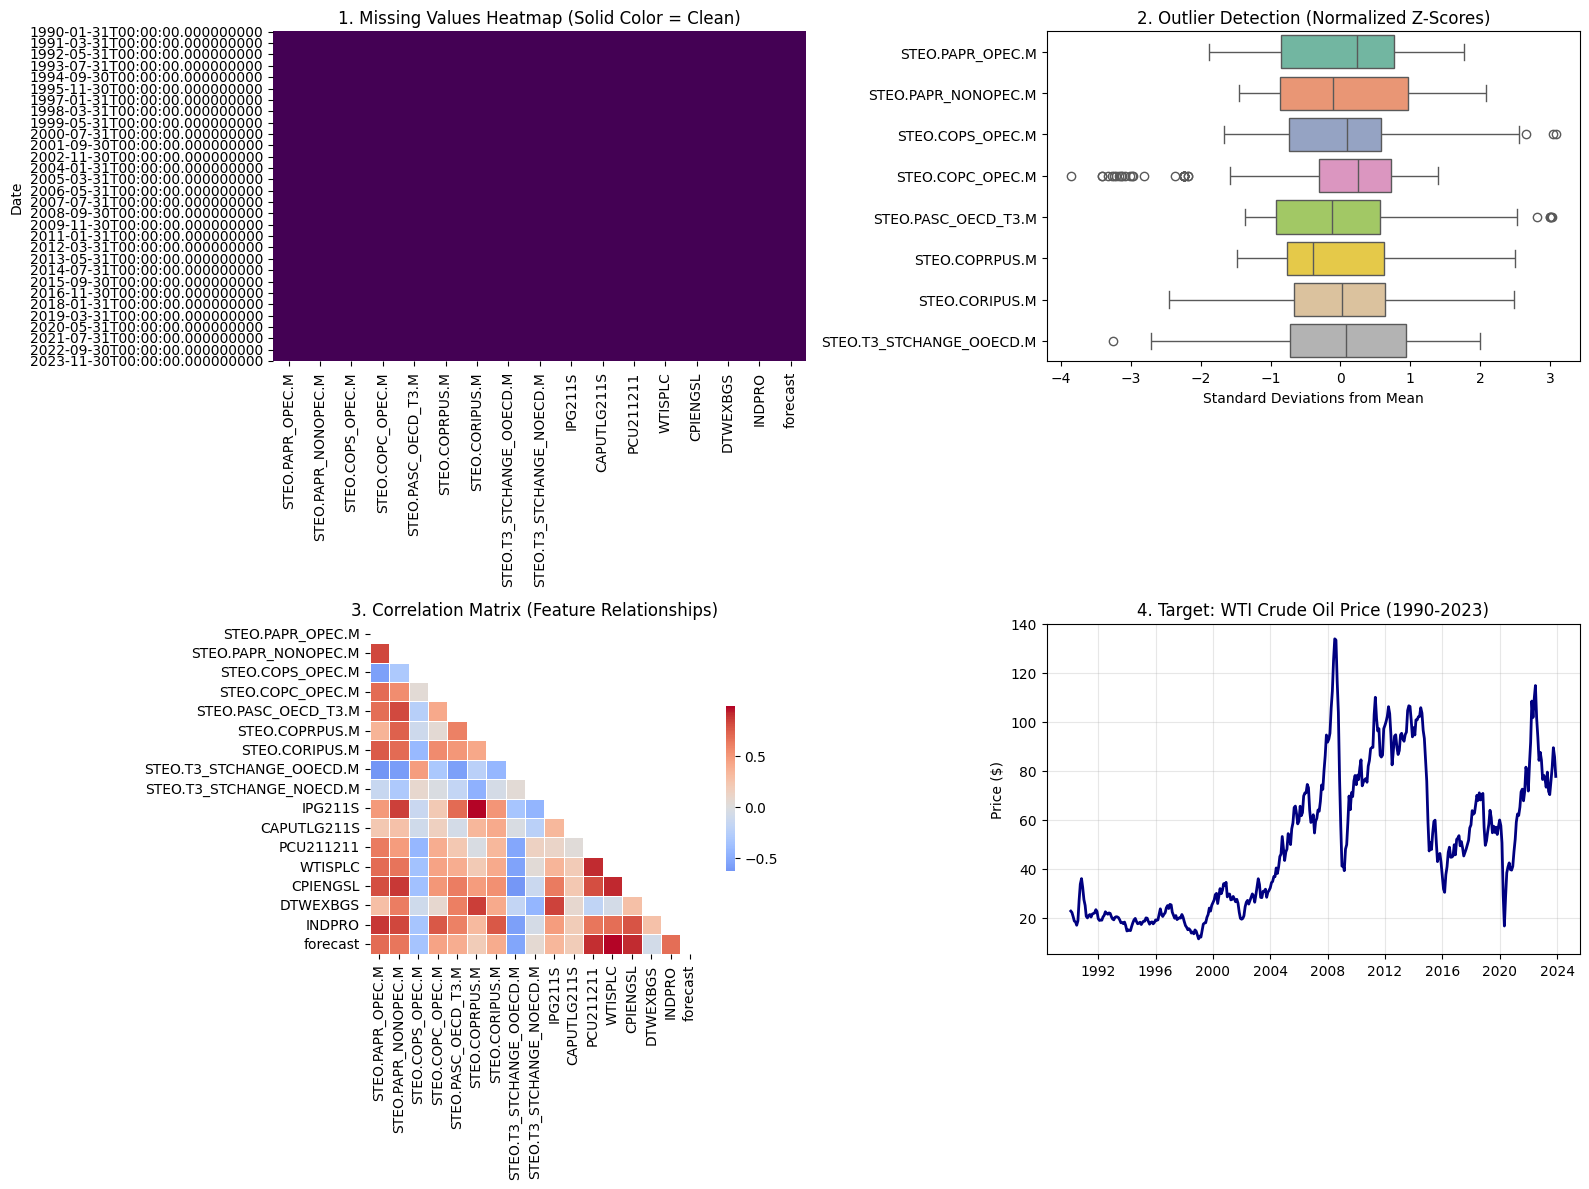


SUCCESS: Plots generated and saved as 'Step5_Data_Cleaning_Report.png'.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# STEP 5: DATA CLEANING VISUALIZATION
print("--- Starting Step 5: EDA & Quality Check ---")

# 1. Load the "Sterilized" Data
try:
    df = pd.read_csv('oil_market_data_complete.csv', index_col=0, parse_dates=True)
    print(f"Loaded dataset: {df.shape}")
except FileNotFoundError:
    print("Error: Run Step 3 first to generate 'oil_market_data_complete.csv'")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis', ax=axes[0, 0])
axes[0, 0].set_title('1. Missing Values Heatmap (Solid Color = Clean)')
axes[0, 0].set_ylabel('Date')
df_norm = (df - df.mean()) / df.std()
sns.boxplot(data=df_norm.iloc[:, :8], orient="h", palette="Set2", ax=axes[0, 1])
axes[0, 1].set_title('2. Outlier Detection (Normalized Z-Scores)')
axes[0, 1].set_xlabel('Standard Deviations from Mean')

corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, square=True,
            linewidths=.5, cbar_kws={"shrink": .5}, ax=axes[1, 0])
axes[1, 0].set_title('3. Correlation Matrix (Feature Relationships)')

axes[1, 1].plot(df.index, df['WTISPLC'], color='navy', linewidth=2)
axes[1, 1].set_title('4. Target: WTI Crude Oil Price (1990-2023)')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].set_ylabel('Price ($)')

plt.tight_layout()
plt.savefig('Step5_Data_Cleaning_Report.png')
plt.show()

print("\nSUCCESS: Plots generated and saved as 'Step5_Data_Cleaning_Report.png'.")

Training Hidden Markov Model...
State 0 is BULL (Low Vol: 0.00534)
State 1 is BEAR (High Vol: 0.06545)


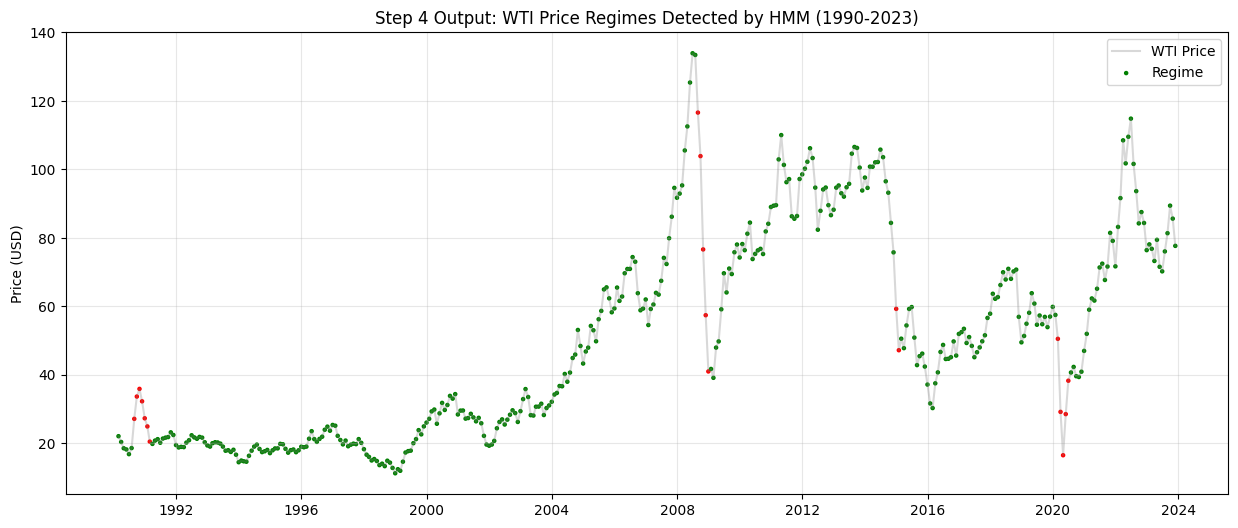


Transition Matrix:
[[0.98412717 0.01587283]
 [0.22914644 0.77085356]]
(Top-left is prob of staying in State 0; Bottom-right is prob of staying in State 1)


In [9]:
# GWP2 STEP 4: HMM DESIGN & REGIME DETECTION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
!pip install hmmlearn
from hmmlearn.hmm import GaussianHMM

# 1. SETUP DATA (Using your GWP1 Variable 'df_final')
# We assume 'df_final' is your cleaned dataframe from GWP1.
# If your variable is named 'df' or 'data', change 'df_final' below.
hmm_data = final_df[['WTISPLC']].copy()

# Calculate Log Returns (Stationary Data for HMM)
hmm_data['Log_Returns'] = np.log(hmm_data['WTISPLC'] / hmm_data['WTISPLC'].shift(1))
hmm_data.dropna(inplace=True) # Drop the first NaN from shifting

# Reshape for hmmlearn (Requires 2D array)
X_train = hmm_data['Log_Returns'].values.reshape(-1, 1)

# 2. MODEL DEFINITION & TRAINING (Student B/C Task)
# We use n_components=2 for Bull (Rise) and Bear (Fall/Crash)
# covariance_type='full' allows each regime to have distinct volatility
print("Training Hidden Markov Model...")
model = GaussianHMM(n_components=2, covariance_type="full", n_iter=100, random_state=42)
model.fit(X_train)

# 3. DECODING REGIMES (Finding the Hidden States)
hidden_states = model.predict(X_train)
hmm_data['Regime'] = hidden_states

# 4. REGIME IDENTIFICATION (Bull vs Bear)
# The model assigns 0/1 arbitrarily. We identify "Bear" by higher volatility (variance).
volatility_0 = model.covars_[0][0][0]
volatility_1 = model.covars_[1][0][0]

if volatility_0 > volatility_1:
    bear_state, bull_state = 0, 1
    print(f"State 0 is BEAR (High Vol: {volatility_0:.5f})")
    print(f"State 1 is BULL (Low Vol: {volatility_1:.5f})")
else:
    bear_state, bull_state = 1, 0
    print(f"State 0 is BULL (Low Vol: {volatility_0:.5f})")
    print(f"State 1 is BEAR (High Vol: {volatility_1:.5f})")

# 5. VISUALIZATION
# Plotting the Regime Detection Results
plt.figure(figsize=(15, 6))
plt.plot(hmm_data.index, hmm_data['WTISPLC'], color='gray', alpha=0.3, label='WTI Price')

# Scatter plot to color-code regimes
# Green for Bull, Red for Bear
colors = ['red' if r == bear_state else 'green' for r in hidden_states]
plt.scatter(hmm_data.index, hmm_data['WTISPLC'], c=colors, s=5, label='Regime (Red=Bear, Green=Bull)')

plt.title('Step 4 Output: WTI Price Regimes Detected by HMM (1990-2023)')
plt.ylabel('Price (USD)')
plt.legend(['WTI Price', 'Regime'])
plt.grid(True, alpha=0.3)
plt.show()

# 6. OUTPUT MODEL PARAMETERS (Useful for Step 6 Write-up)
print("\nTransition Matrix:")
print(model.transmat_)
print("(Top-left is prob of staying in State 0; Bottom-right is prob of staying in State 1)")

  0%|          | 0/1000000 [00:00<?, ?it/s]

--- Step 9a: Learned Edges from Hill Climb Search ---
[('STEO.PAPR_NONOPEC.M', 'STEO.PAPR_OPEC.M'), ('STEO.PAPR_NONOPEC.M', 'INDPRO'), ('STEO.PAPR_NONOPEC.M', 'STEO.PASC_OECD_T3.M'), ('STEO.PAPR_NONOPEC.M', 'DTWEXBGS'), ('STEO.PAPR_NONOPEC.M', 'STEO.COPC_OPEC.M'), ('STEO.PAPR_NONOPEC.M', 'STEO.T3_STCHANGE_NOECD.M'), ('STEO.COPS_OPEC.M', 'IPG211S'), ('STEO.PASC_OECD_T3.M', 'PCU211211'), ('STEO.PASC_OECD_T3.M', 'STEO.T3_STCHANGE_OOECD.M'), ('IPG211S', 'STEO.PAPR_NONOPEC.M'), ('IPG211S', 'STEO.COPRPUS.M'), ('PCU211211', 'WTISPLC'), ('WTISPLC', 'forecast'), ('WTISPLC', 'CPIENGSL'), ('CPIENGSL', 'CAPUTLG211S'), ('INDPRO', 'STEO.CORIPUS.M')]


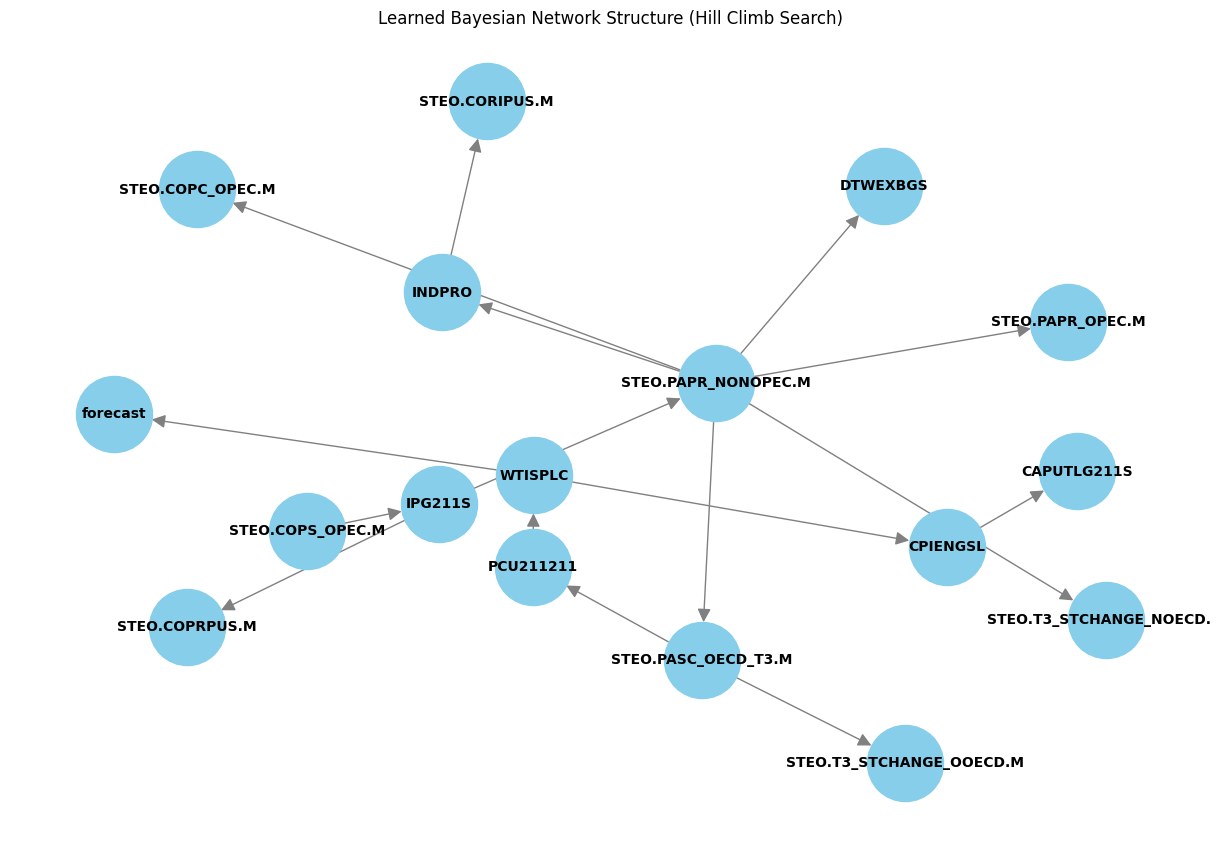

In [8]:
# --- STEP 9: MINIMAL WORKING EXAMPLE OF HILL CLIMB SEARCH ---

# 1. Import necessary libraries
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.estimators import HillClimbSearch, BIC  # UPDATED: 'BicScore' is now 'BIC'
np.random.seed(42)
# 2. Data Preparation for Structure Learning
# We need to use the cleaned dataset. Assuming 'df' is your final dataframe from Step 1/2.
# If 'df' is not available, reload it:
try:
    df_hc = pd.read_csv('oil_market_data_complete.csv', index_col=0)
except FileNotFoundError:
    print("Data file not found. Using variable 'df' from memory.")
    # Ensure df exists in your environment, otherwise this will fail
    if 'df' in locals():
        df_hc = df.copy()
    else:
        # Create a dummy dataframe for the example if 'df' doesn't exist
        print("Creating dummy data for demonstration...")
        df_hc = pd.DataFrame(np.random.randint(0, 5, size=(100, 5)), columns=['A', 'B', 'C', 'D', 'E'])

# 3. Discretization
# Bayesian Network structure learning often works best with discrete data.
# We will discretize continuous variables into 5 bins (quintiles).
df_discrete = pd.DataFrame()
for col in df_hc.columns:
    try:
        df_discrete[col] = pd.qcut(df_hc[col], q=5, labels=False, duplicates='drop')
    except ValueError:
        # Handle cases with too many duplicate values (e.g., encoded categorical data)
        df_discrete[col] = df_hc[col]

# 4. Initialize Hill Climb Search
# UPDATED: Use the 'BIC' class instead of 'BicScore'
hc = HillClimbSearch(df_discrete)
best_model = hc.estimate(scoring_method=BIC(df_discrete))

# 5. Display the Learned Structure (Edges)
print("--- Step 9a: Learned Edges from Hill Climb Search ---")
print(best_model.edges())

# 6. Visualization of the Learned Graph
plt.figure(figsize=(12, 8))
G = nx.DiGraph()
G.add_edges_from(best_model.edges())

# Layout for the nodes
pos = nx.spring_layout(G, k=0.5, iterations=50)

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color='skyblue',
    font_size=10,
    font_weight='bold',
    arrowsize=20,
    edge_color='gray'
)
plt.title("Learned Bayesian Network Structure (Hill Climb Search)")
plt.show()